<a href="https://colab.research.google.com/github/saketh-varma06/DL_ASSIGNMENTS/blob/main/DL_ASS_08.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Using device: cpu
This may take some time because the dataset is large.


100%|██████████| 787M/787M [00:33<00:00, 24.9MB/s]

Extracting files...


Dataset downloaded successfully.
Downloaded location:
/root/.cache/kagglehub/datasets/karakaggle/kaggle-cat-vs-dog-dataset/versions/1

Dataset path: /root/.cache/kagglehub/datasets/karakaggle/kaggle-cat-vs-dog-dataset/versions/1/kagglecatsanddogs_3367a/PetImages
Folders: ['Dog', 'Cat']

Checking image files...
This may take a little time.


/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))



Total valid images: 24959
Classes: ['Cat', 'Dog']

Training images: 19967
Testing images : 4992

DataLoaders created successfully.


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


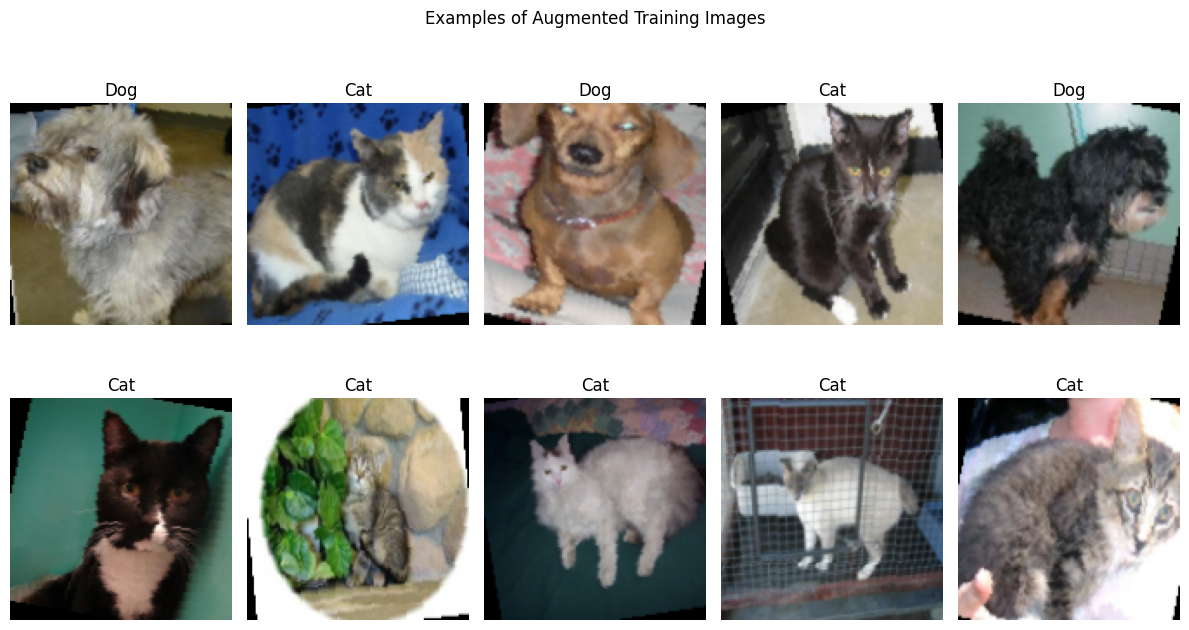


CNN Model:
CatsDogsCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=32768, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=256, out_features=2, bias=True)
  )
)

Loss Function: CrossEntropyLoss
Optimizer: Adam
Learning Rate: 0.001
Epoch [1/5] Loss: 0.6426 Accuracy: 61.52%
Epoch [2/5] Loss: 0.5463 Accuracy: 71.93%
Epoch [3/5]

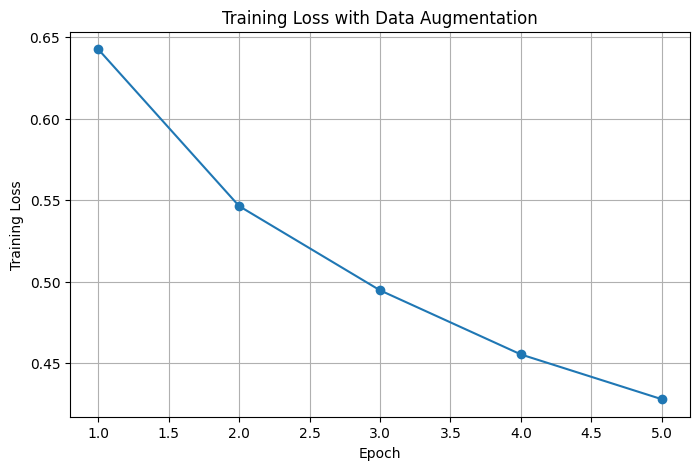

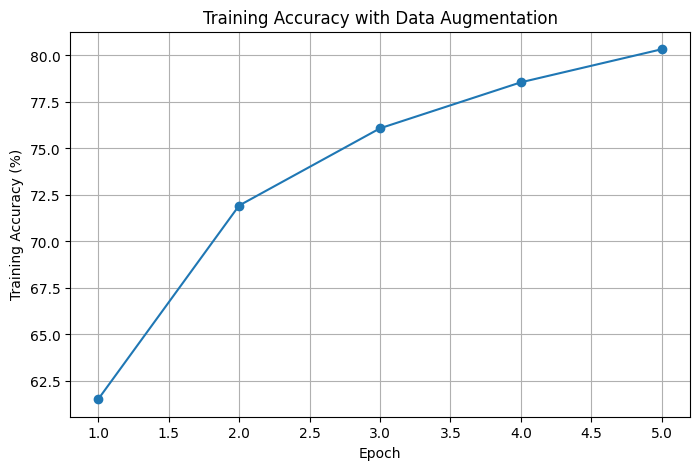

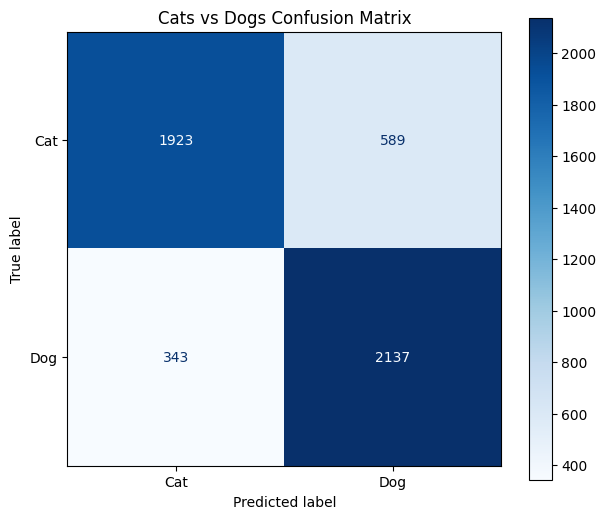

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


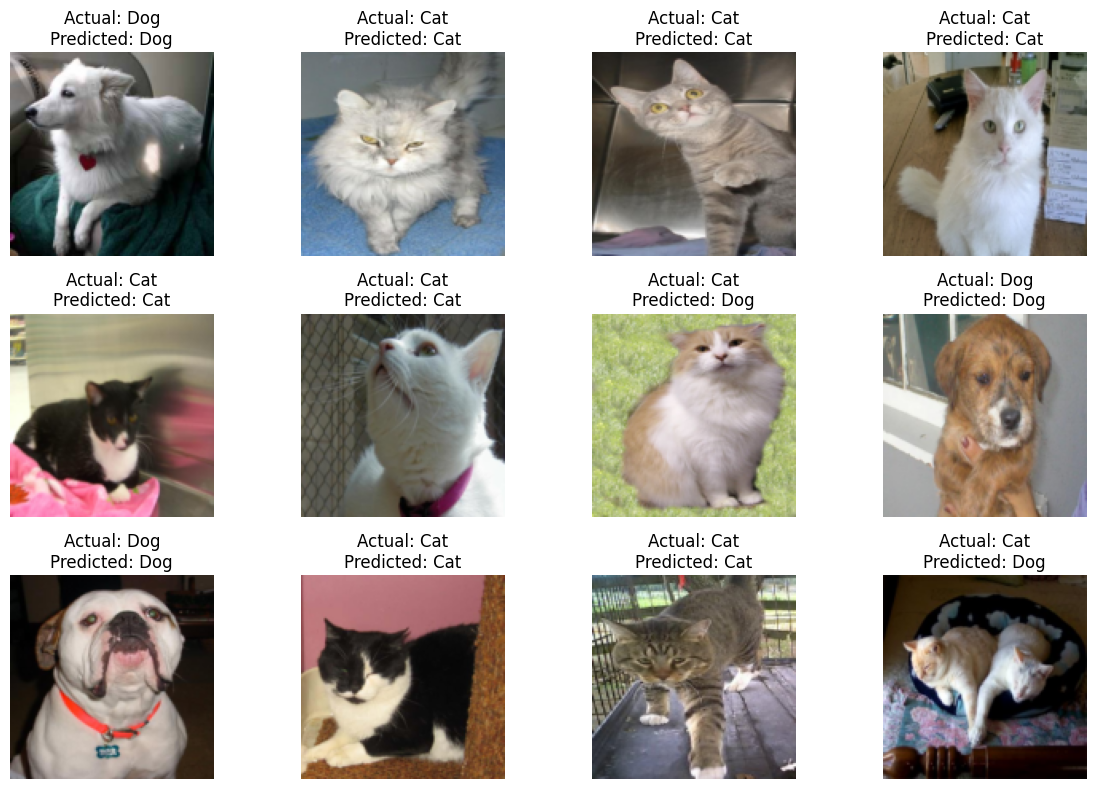


FINAL RESULTS
Test Accuracy : 81.33%
Precision     : 81.65%
Recall        : 81.33%
F1 Score      : 81.29%

CONCLUSION

The Cats vs Dogs dataset was successfully loaded and
preprocessed using PyTorch.

Data augmentation techniques including Random Horizontal
Flip, Random Rotation and Random Resized Crop were applied
to the training images.

A Convolutional Neural Network (CNN) was implemented for
binary classification of cats and dogs.

The model was trained using the Adam optimizer and
CrossEntropyLoss.

The training loss and accuracy were recorded for every
epoch and visualized using graphs.

The model was evaluated using Accuracy, Precision,
Recall and F1 Score.

A confusion matrix was also generated to understand
the classification performance of the model.

Data augmentation provides different variations of the
training images and helps the CNN learn more general
visual features. This can help reduce overfitting and
improve performance on unseen images.

Overall, the CNN successfu

In [ ]:
# ============================================================
# IMPLEMENTING DATA AUGMENTATION FOR IMAGE DATA
# CATS VS DOGS CLASSIFICATION USING PYTORCH
# ============================================================


# ============================================================
# 1. INSTALL AND IMPORT REQUIRED LIBRARIES
# ============================================================

!pip -q install kagglehub

import os
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

import torchvision
import torchvision.transforms as transforms

from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, random_split, Subset

from PIL import Image

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)


# ============================================================
# 2. SET RANDOM SEED AND DEVICE
# ============================================================

torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

if torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print("Using device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


# ============================================================
# 3. DOWNLOAD CATS VS DOGS DATASET
# ============================================================

import kagglehub

print("Downloading Cats vs Dogs dataset...")
print("This may take some time because the dataset is large.")

dataset_download_path = kagglehub.dataset_download(
    "karakaggle/kaggle-cat-vs-dog-dataset"
)

print("Dataset downloaded successfully.")
print("Downloaded location:")
print(dataset_download_path)


# ============================================================
# 4. FIND PETIMAGES FOLDER
# ============================================================

dataset_path = None

for root, dirs, files in os.walk(dataset_download_path):

    folder_names = [d.lower() for d in dirs]

    if "cat" in folder_names and "dog" in folder_names:

        dataset_path = root
        break


if dataset_path is None:

    raise FileNotFoundError(
        "Could not find Cat and Dog folders in the dataset."
    )


print("\nDataset path:", dataset_path)
print("Folders:", os.listdir(dataset_path))


# ============================================================
# 5. CHECK IMAGE FILES
# ============================================================

def check_image(path):

    try:

        with Image.open(path) as img:
            img.verify()

        return True

    except:

        return False


print("\nChecking image files...")
print("This may take a little time.")


# ============================================================
# 6. DATA AUGMENTATION FOR TRAINING
# ============================================================

train_transform = transforms.Compose([

    # Resize image
    transforms.Resize((128, 128)),

    # ----------------------------
    # DATA AUGMENTATION
    # ----------------------------

    # Randomly flip image horizontally
    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    # Randomly rotate image
    transforms.RandomRotation(
        15
    ),

    # Randomly crop and resize
    transforms.RandomResizedCrop(
        128,
        scale=(0.8, 1.0)
    ),

    # Convert image to tensor
    transforms.ToTensor(),

    # Normalize image
    transforms.Normalize(
        mean=(0.5, 0.5, 0.5),
        std=(0.5, 0.5, 0.5)
    )
])


# ============================================================
# 7. PREPROCESSING FOR TEST DATA
# ============================================================

# No random augmentation is applied to test images.

test_transform = transforms.Compose([

    transforms.Resize((128, 128)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=(0.5, 0.5, 0.5),
        std=(0.5, 0.5, 0.5)
    )
])


# ============================================================
# 8. LOAD TRAINING DATASET
# ============================================================

train_full_dataset = ImageFolder(
    root=dataset_path,
    transform=train_transform,
    is_valid_file=check_image
)

print("\nTotal valid images:", len(train_full_dataset))
print("Classes:", train_full_dataset.classes)

# Expected:
# ['Cat', 'Dog']


# ============================================================
# 9. LOAD TEST DATASET
# ============================================================

test_full_dataset = ImageFolder(
    root=dataset_path,
    transform=test_transform,
    is_valid_file=check_image
)


# ============================================================
# 10. SPLIT DATASET
# ============================================================

total_size = len(train_full_dataset)

train_size = int(
    0.8 * total_size
)

test_size = total_size - train_size


# Create the same random indices for both datasets
generator = torch.Generator().manual_seed(42)

train_subset, test_subset = random_split(
    range(total_size),
    [train_size, test_size],
    generator=generator
)


# Create actual datasets using the same indices
train_dataset = Subset(
    train_full_dataset,
    train_subset.indices
)

test_dataset = Subset(
    test_full_dataset,
    test_subset.indices
)


print("\nTraining images:", len(train_dataset))
print("Testing images :", len(test_dataset))


# ============================================================
# 11. CREATE DATALOADERS
# ============================================================

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("\nDataLoaders created successfully.")


# ============================================================
# 12. DISPLAY AUGMENTED IMAGES
# ============================================================

images, labels = next(
    iter(train_loader)
)

plt.figure(figsize=(12, 7))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    image = images[i]

    # Convert normalized image back
    image = image * 0.5 + 0.5

    image = image.permute(
        1, 2, 0
    )

    image = torch.clamp(
        image,
        0,
        1
    )

    plt.imshow(image)

    if labels[i].item() == 0:
        title = "Cat"
    else:
        title = "Dog"

    plt.title(title)

    plt.axis("off")

plt.suptitle(
    "Examples of Augmented Training Images"
)

plt.tight_layout()
plt.show()


# ============================================================
# 13. BUILD CNN MODEL
# ============================================================

class CatsDogsCNN(nn.Module):

    def __init__(self):

        super(CatsDogsCNN, self).__init__()

        # ----------------------------------------------------
        # CONVOLUTIONAL FEATURE EXTRACTION
        # ----------------------------------------------------

        self.features = nn.Sequential(

            # Block 1
            nn.Conv2d(
                in_channels=3,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.MaxPool2d(
                kernel_size=2
            ),


            # Block 2
            nn.Conv2d(
                in_channels=32,
                out_channels=64,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.MaxPool2d(
                kernel_size=2
            ),


            # Block 3
            nn.Conv2d(
                in_channels=64,
                out_channels=128,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.MaxPool2d(
                kernel_size=2
            )
        )


        # ----------------------------------------------------
        # CLASSIFICATION
        # ----------------------------------------------------

        self.classifier = nn.Sequential(

            nn.Flatten(),

            # 128 x 16 x 16
            nn.Linear(
                128 * 16 * 16,
                256
            ),

            nn.ReLU(),

            # Dropout helps prevent overfitting
            nn.Dropout(
                0.5
            ),

            # Binary classification
            nn.Linear(
                256,
                2
            )
        )


    def forward(self, x):

        x = self.features(x)

        x = self.classifier(x)

        return x


# Create model
model = CatsDogsCNN().to(device)

print("\nCNN Model:")
print(model)


# ============================================================
# 14. DEFINE LOSS FUNCTION AND OPTIMIZER
# ============================================================

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("\nLoss Function: CrossEntropyLoss")
print("Optimizer: Adam")
print("Learning Rate: 0.001")


# ============================================================
# 15. TRAIN THE MODEL
# ============================================================

epochs = 5

train_losses = []
train_accuracies = []


for epoch in range(epochs):

    model.train()

    running_loss = 0.0

    correct = 0
    total = 0


    for images, labels in train_loader:

        # Move data to GPU/CPU
        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )


        # --------------------------------------------
        # CLEAR GRADIENTS
        # --------------------------------------------

        optimizer.zero_grad()


        # --------------------------------------------
        # FORWARD PASS
        # --------------------------------------------

        outputs = model(images)


        # --------------------------------------------
        # CALCULATE LOSS
        # --------------------------------------------

        loss = criterion(
            outputs,
            labels
        )


        # --------------------------------------------
        # BACKPROPAGATION
        # --------------------------------------------

        loss.backward()


        # --------------------------------------------
        # UPDATE WEIGHTS
        # --------------------------------------------

        optimizer.step()


        # --------------------------------------------
        # STORE LOSS
        # --------------------------------------------

        running_loss += loss.item()


        # --------------------------------------------
        # CALCULATE ACCURACY
        # --------------------------------------------

        _, predicted = torch.max(
            outputs,
            1
        )

        total += labels.size(0)

        correct += (
            predicted == labels
        ).sum().item()


    # Calculate epoch results
    epoch_loss = (
        running_loss /
        len(train_loader)
    )

    epoch_accuracy = (
        100 * correct / total
    )


    train_losses.append(
        epoch_loss
    )

    train_accuracies.append(
        epoch_accuracy
    )


    print(
        f"Epoch [{epoch + 1}/{epochs}] "
        f"Loss: {epoch_loss:.4f} "
        f"Accuracy: {epoch_accuracy:.2f}%"
    )


# ============================================================
# 16. EVALUATE THE MODEL
# ============================================================

model.eval()

y_true = []
y_pred = []


with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        outputs = model(images)

        _, predicted = torch.max(
            outputs,
            1
        )


        y_true.extend(
            labels.numpy()
        )

        y_pred.extend(
            predicted.cpu().numpy()
        )


# ============================================================
# 17. CALCULATE PERFORMANCE METRICS
# ============================================================

accuracy = accuracy_score(
    y_true,
    y_pred
)

precision = precision_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)


# ============================================================
# 18. DISPLAY EVALUATION RESULTS
# ============================================================

print("\n============================================================")
print("EVALUATION RESULTS")
print("============================================================")

print(
    f"Accuracy  : {accuracy * 100:.2f}%"
)

print(
    f"Precision : {precision * 100:.2f}%"
)

print(
    f"Recall    : {recall * 100:.2f}%"
)

print(
    f"F1 Score  : {f1 * 100:.2f}%"
)


# ============================================================
# 19. PLOT TRAINING LOSS
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, epochs + 1),
    train_losses,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")

plt.title(
    "Training Loss with Data Augmentation"
)

plt.grid()

plt.show()


# ============================================================
# 20. PLOT TRAINING ACCURACY
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, epochs + 1),
    train_accuracies,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training Accuracy (%)")

plt.title(
    "Training Accuracy with Data Augmentation"
)

plt.grid()

plt.show()


# ============================================================
# 21. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred
)

fig, ax = plt.subplots(
    figsize=(7, 6)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Cat", "Dog"]
)

disp.plot(
    ax=ax,
    cmap="Blues"
)

plt.title(
    "Cats vs Dogs Confusion Matrix"
)

plt.show()


# ============================================================
# 22. DISPLAY ACTUAL VS PREDICTED IMAGES
# ============================================================

images, labels = next(
    iter(test_loader)
)

images_device = images.to(device)


with torch.no_grad():

    outputs = model(
        images_device
    )

    _, predictions = torch.max(
        outputs,
        1
    )


plt.figure(figsize=(12, 8))


for i in range(12):

    plt.subplot(
        3,
        4,
        i + 1
    )


    # Convert image back
    image = images[i]

    image = image * 0.5 + 0.5

    image = image.permute(
        1,
        2,
        0
    )

    image = torch.clamp(
        image,
        0,
        1
    )


    plt.imshow(image)


    # Actual label
    if labels[i].item() == 0:
        actual = "Cat"
    else:
        actual = "Dog"


    # Predicted label
    if predictions[i].item() == 0:
        predicted = "Cat"
    else:
        predicted = "Dog"


    plt.title(
        f"Actual: {actual}\n"
        f"Predicted: {predicted}"
    )

    plt.axis("off")


plt.tight_layout()
plt.show()


# ============================================================
# 23. FINAL RESULTS
# ============================================================

print("\n============================================================")
print("FINAL RESULTS")
print("============================================================")

print(
    f"Test Accuracy : {accuracy * 100:.2f}%"
)

print(
    f"Precision     : {precision * 100:.2f}%"
)

print(
    f"Recall        : {recall * 100:.2f}%"
)

print(
    f"F1 Score      : {f1 * 100:.2f}%"
)


# ============================================================
# 24. CONCLUSION
# ============================================================

print("\n============================================================")
print("CONCLUSION")
print("============================================================")

print("""
The Cats vs Dogs dataset was successfully loaded and
preprocessed using PyTorch.

Data augmentation techniques including Random Horizontal
Flip, Random Rotation and Random Resized Crop were applied
to the training images.

A Convolutional Neural Network (CNN) was implemented for
binary classification of cats and dogs.

The model was trained using the Adam optimizer and
CrossEntropyLoss.

The training loss and accuracy were recorded for every
epoch and visualized using graphs.

The model was evaluated using Accuracy, Precision,
Recall and F1 Score.

A confusion matrix was also generated to understand
the classification performance of the model.

Data augmentation provides different variations of the
training images and helps the CNN learn more general
visual features. This can help reduce overfitting and
improve performance on unseen images.

Overall, the CNN successfully learned to distinguish
between cats and dogs using augmented image data.
""")